# JPM 63-Day Stock Price Forecast

## Step 1: Set Up the Notebook

In [1]:
import os
import sys
import subprocess

print("Python interpreter:", sys.executable)
print("Python version    :", sys.version.split()[0])

Python interpreter: c:\Users\nicol\OneDrive\Desktop\school\4th\4.1\BI\labs\TimeSeriesForecastingandNeuralNetworks\.venv\Scripts\python.exe
Python version    : 3.12.10


In [2]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler

from tslab import config
from tslab.data import load_market_data
from tslab.features import make_dataset, ALL_FEATURES
from tslab.validation import walk_forward_splits, walk_forward_predict
from tslab.metrics import out_of_sample_r2, rmse, directional_accuracy

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 5)

## Step 2: Prepare the Data

Load the shared JPM stock data and prepare the predictor variables
required to generate the 63-business-day forecast.

In [3]:
frame = load_market_data()

latest_features = make_dataset(frame, horizon=1).iloc[[-1]][ALL_FEATURES]

last_close = float(frame["Close"].iloc[-1])
last_date = frame.index[-1]

print(f"Target stock: {config.TARGET_TICKER}")
print(f"Latest data: {last_date.date()}, closing price {last_close:.2f}")

Loaded 2981 trading days of JPM, 2015-01-02 to 2026-11-09, with 7 predictor series.
Target stock: JPM
Latest data: 2026-11-09, closing price 342.08


## Step 3: Define the Forecasting Model

Use Histogram Gradient Boosting to predict future stock returns
and estimate the lower and upper forecast bounds.

In [4]:
def make_boosting(loss="squared_error", quantile=None):
    return HistGradientBoostingRegressor(
        loss=loss,
        quantile=quantile,
        max_depth=2,
        learning_rate=0.03,
        max_iter=150,
        min_samples_leaf=40,
        l2_regularization=1.0,
        random_state=config.SEED
    )

## Step 4: Generate the 63-Day Forecast

Use the direct forecasting method to predict JPM stock prices
for the next 63 business days. Train three models for each
horizon to generate a central forecast and a 10th to 90th
percentile uncertainty range.

In [5]:
path_rows = []
started = time.time()
scaler = None

for horizon in range(1, 64):
    data_h = make_dataset(frame, horizon=horizon).dropna(subset=["target_return"])
    X_h, y_h = data_h[ALL_FEATURES], data_h["target_return"]
    scaler = StandardScaler().fit(X_h)
    X_scaled, today = scaler.transform(X_h), scaler.transform(latest_features)

    point = make_boosting().fit(X_scaled, y_h).predict(today)[0]
    low = make_boosting("quantile", 0.10).fit(X_scaled, y_h).predict(today)[0]
    high = make_boosting("quantile", 0.90).fit(X_scaled, y_h).predict(today)[0]

    # Sort predictions to prevent crossing forecast bounds
    low, point, high = sorted([low, point, high])

    path_rows.append({
        "horizon_days": horizon,
        "date": last_date + pd.offsets.BDay(horizon),
        "forecast_close": last_close * np.exp(point),
        "lower_10": last_close * np.exp(low),
        "upper_90": last_close * np.exp(high),
    })

print(f"Done in {time.time() - started:.0f} seconds")

forecast_path = pd.DataFrame(path_rows).set_index("date")
forecast_path.round(2).iloc[[0, 4, 20, 41, 62]]

Done in 167 seconds


,horizon_days,forecast_close,lower_10,upper_90
date,,,,
2026-11-10,1,338.32,335.79,348.59
2026-11-16,5,344.17,323.59,358.20
2026-12-08,21,345.67,318.05,377.68
2027-01-06,42,360.06,324.81,393.21
2027-02-04,63,372.79,333.36,416.11


## Step 5: Visualize the Forecast

Plot historical JPM closing prices alongside the 63-day
forecast and its uncertainty range to show the predicted
price movement and associated risk.

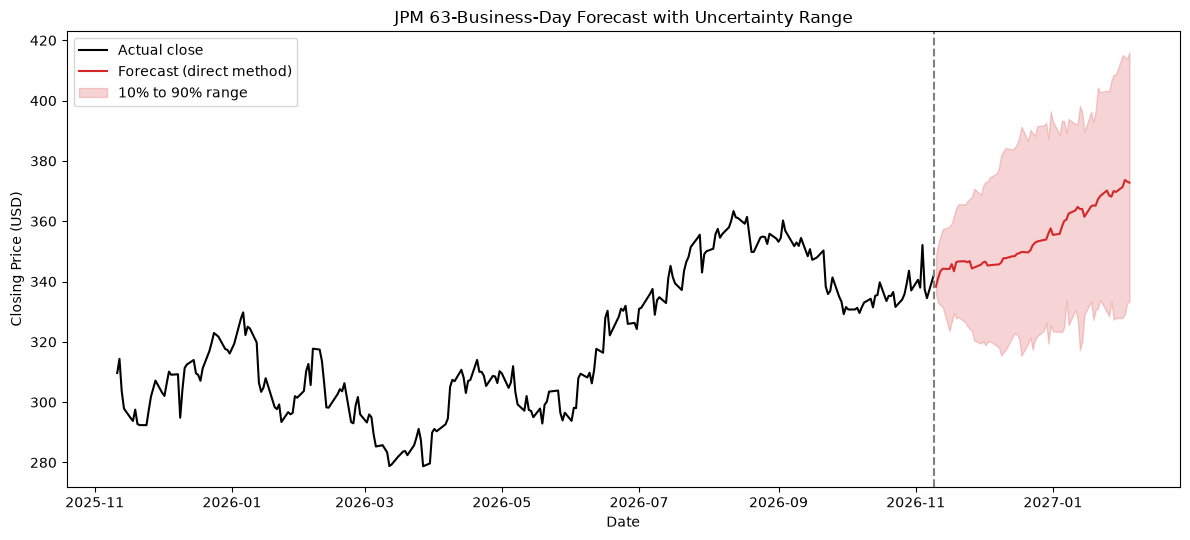

In [6]:
history = frame["Close"].iloc[-250:]

plt.figure(figsize=(12, 5.5))

plt.plot(history, color="black", label="Actual close")

plt.plot(
    forecast_path["forecast_close"],
    color="tab:red",
    label="Forecast (direct method)"
)

plt.fill_between(
    forecast_path.index,
    forecast_path["lower_10"],
    forecast_path["upper_90"],
    color="tab:red",
    alpha=0.2,
    label="10% to 90% range"
)

plt.axvline(last_date, color="grey", linestyle="--")

plt.title("JPM 63-Business-Day Forecast with Uncertainty Range")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.legend()
plt.tight_layout()
plt.show()

## Step 6: Validate the Forecast

Check that the forecast contains 63 business days, has no
missing values and that the forecast bounds are correctly ordered.

In [7]:
print("Total forecast days:", len(forecast_path))
print("First forecast date:", forecast_path.index.min().date())
print("Last forecast date:", forecast_path.index.max().date())
print("Missing values:", forecast_path.isna().sum().sum())
print("Duplicate dates:", forecast_path.index.duplicated().sum())

print("Valid forecast bounds:", (
    (forecast_path["lower_10"] <= forecast_path["forecast_close"]) &
    (forecast_path["forecast_close"] <= forecast_path["upper_90"])
).all())

print("Correct business days:", forecast_path.index.equals(
    pd.bdate_range(start=last_date + pd.offsets.BDay(1), periods=63)
))

Total forecast days: 63
First forecast date: 2026-11-10
Last forecast date: 2027-02-04
Missing values: 0
Duplicate dates: 0
Valid forecast bounds: True
Correct business days: True


## Step 7: Export the Forecast for Power BI

Export the 63-business-day forecast to a CSV file containing
the date, central forecast, lower bound and upper bound.

In [8]:
os.makedirs(config.DATA_DIR, exist_ok=True)

export = forecast_path.reset_index()

export = export.rename(columns={
    "forecast_close": "forecast",
    "lower_10": "lower",
    "upper_90": "upper"
})

export = export[["date", "forecast", "lower", "upper"]]

export.to_csv(config.DATA_DIR / "forecast_basic.csv", index=False)

print("Saved", len(export), "rows to", config.DATA_DIR / "forecast_basic.csv")

Saved 63 rows to C:\Users\nicol\OneDrive\Desktop\school\4th\4.1\BI\labs\TimeSeriesForecastingandNeuralNetworks\data\forecast_basic.csv


## Step 8: Verify the Exported CSV

Confirm that the exported file contains 63 forecast rows
and the four required columns for Power BI.

In [9]:
saved_forecast = pd.read_csv(config.DATA_DIR / "forecast_basic.csv")

print("Number of rows:", len(saved_forecast))
print("Number of columns:", len(saved_forecast.columns))
print("Column names:", saved_forecast.columns.tolist())
print("Missing values:", saved_forecast.isna().sum().sum())

saved_forecast.head()

Number of rows: 63
Number of columns: 4
Column names: ['date', 'forecast', 'lower', 'upper']
Missing values: 0


,date,forecast,lower,upper
0,2026-11-10,338.320938,335.792713,348.591484
1,2026-11-11,341.262104,332.865243,352.420427
2,2026-11-12,343.459556,332.205391,355.024235
3,2026-11-13,344.241179,331.488617,357.340177
4,2026-11-16,344.171121,323.593847,358.198806
